In [157]:
%cd C:/Users/yjjby/Documents/projects/Topic-Conceptualization/iterative_codebook_making

import os
import json
from importlib import reload
from pathlib import Path
import shutil

import polars as pl
pl.Config.set_tbl_rows(100)
pl.Config.set_fmt_str_lengths(1000)
from dotenv import load_dotenv
import codebook_iteration_funcs
reload(codebook_iteration_funcs)
from codebook_iteration_funcs import (
    model_folder, load_documents, codebook_input,
    run_classifications, retrieve_classification_batch, review_coding,
    generate_codebook, revise_codebook, parse_codebook, compare_models, freeze_codebook,
)

load_dotenv('../.env')
api_key = os.environ.get('OPENROUTER_API_KEY')

model_a = 'openai/gpt-6-luna'
model_a_safe_name = model_folder(model_a)
model_b = 'deepseek/deepseek-v4.1-flash'
model_b_safe_name = model_folder(model_b)

session = 'emotive_rhetoric'
os.chdir(session)
print(os.getcwd())

classify_w_codebook_prompt = Path("prompts/classify_w_codebook.txt").read_text(encoding='utf-8')
def load_dataset(dataset_number):
    path = f"data/emotive_rhetoric_{dataset_number}.csv"
    df = pl.read_csv(path, columns=["document_id", "text"], infer_schema=False)
    return df
def copy_codebook(source, to_folder, to_name, note=""):
    to_folder = Path(to_folder)
    to_folder.mkdir(parents=True, exist_ok=True)
    destination = to_folder
    shutil.copy(source, to_folder)
    if note:
        (to_folder / f"{to_name}.txt").write_text(note, encoding="utf-8")
    return destination

C:\Users\yjjby\Documents\projects\Topic-Conceptualization\iterative_codebook_making
C:\Users\yjjby\Documents\projects\Topic-Conceptualization\iterative_codebook_making\emotive_rhetoric


# I. Initial codebook generation

## 1. Model A receives and codes dataset_0, 25x
        Input: dataset_0
        Output: coded dataset_0, 25x

In [ ]:
dataset_0 = load_dataset(0)
prompt_0 = Path('prompts/initial_classification.txt').read_text(encoding='utf-8')

In [ ]:
dry_run = True  # Preview first; set False to send.
mode = "stream"
dir_0 = Path('out', 'I_initial_codebook_generation', model_a_safe_name, 'initial_coding_dataset_0', mode)
initial_request = run_classifications(
    documents = dataset_0,
    prompt = prompt_0,
    model = model_a + ":nitro",
    out_dir = dir_0,
    codebook= None,
    mode = mode,
    n_runs = 25,
    provider = None,
    dry_run =dry_run,
    api_key = api_key,
)
initial_request

In [ ]:
# Batch only: rerun until completed.
if mode == 'batch':
    initial_batch = retrieve_classification_batch(api_key, dir_0)
    print(initial_batch['status'], initial_batch.get('request_counts'))

completed {'total': 25, 'completed': 25, 'failed': 0}


Krippendorff's alpha: 0.8492


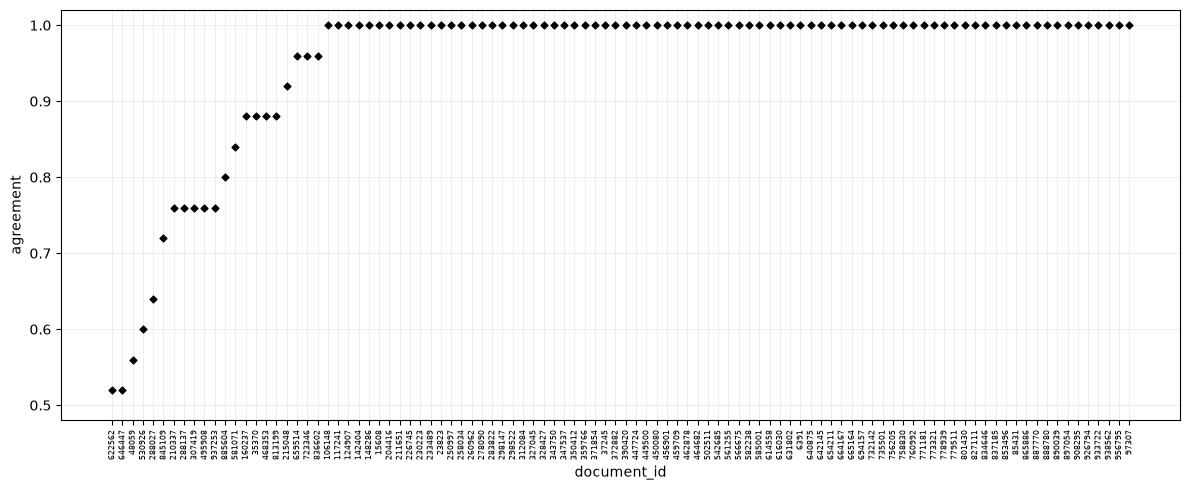

In [ ]:
# Parse saved outputs; this cell sends no requests.
order_0 = review_coding(dir_0)

## 2. Generate Codebook A.0.0
Model A receives its coding of dataset_0 (distribution over 25), and is asked to generate a codebook, choosing decision rules where its coding is inconsistent. This becomes Codebook A.0.0

        Input: coded dataset_0
        Output: Codebook A.0.0

In [ ]:
A00_input = codebook_input(
    load_documents(dir_0 / 'documents.csv'),
    pl.read_csv(dir_0 / 'classifications.csv',
                schema_overrides={'document_id': pl.String, 'label': pl.String}))

generate_A00_prompt = Path('prompts/generate_A00.txt').read_text(encoding='utf-8')

A00_dir = Path('out', 'I_initial_codebook_generation', model_a_safe_name, 'codebooks_A0K', "A.0.0")

In [ ]:
dry_run = False  # Preview first; set False to send.
codebook_gen = generate_codebook(
    coded_documents = A00_input,
    prompt = generate_A00_prompt,
    model = model_a,
    out_dir = A00_dir,
    previous_codebook = None,
    mode = "stream",
    provider = None,
    dry_run = dry_run,
    api_key = api_key,
)

In [ ]:
codebook_A00 = parse_codebook(A00_dir, codebook_id="A.0.0")

WindowsPath('out/I_initial_codebook_generation/openai_gpt-6-luna/codebooks_A0K/A.0.0')

## 3. Consistency check of A.0.k (starting with k=0)
Model A codes dataset_0 using Codebook A.0.k, 25x

        Input: dataset_0, Codebook A.0.k
        Output: coded dataset_0, 25x
        Empirical: Agreement across 25x

In [ ]:
k = 1 # k = 0 for first round
codebook_name = f"A.0.{k}"
A0K_dir = Path('out', 'I_initial_codebook_generation', model_a_safe_name, 'codebooks_A0K', codebook_name)
A0K_codebook_path = A0K_dir / f"codebook_{codebook_name}.json"
codebook_A0K = json.loads(
    (A0K_codebook_path).read_text(encoding="utf-8")
)

In [ ]:
# Preview first. Set False and rerun this cell to send.
dry_run = False
mode = "stream"
A0K_dir_consistency = A0K_dir / mode
check_request = run_classifications(
    documents = dataset_0,
    prompt = classify_w_codebook_prompt,
    codebook = codebook_A0K,
    model = model_a + ":nitro",
    out_dir = A0K_dir_consistency,
    api_key = api_key,
    provider = None,
    n_runs = 25,
    dry_run = dry_run,
)
check_request

Run 1/25: saved
Run 2/25: saved
Run 3/25: saved
Run 4/25: saved
Run 5/25: saved
Run 6/25: saved
Run 7/25: saved
Run 8/25: saved
Run 9/25: saved
Run 10/25: saved
Run 11/25: saved
Run 12/25: saved
Run 13/25: saved
Run 14/25: saved
Run 15/25: saved
Run 16/25: saved
Run 17/25: saved
Run 18/25: saved
Run 19/25: saved
Run 20/25: saved
Run 21/25: saved
Run 22/25: saved
Run 23/25: saved
Run 24/25: saved
Run 25/25: saved


In [ ]:
# Batch only: check until completed. Skip for streaming.
if mode == "batch":
    batch = retrieve_classification_batch(api_key, A0K_dir_consistency)
    print(batch['status'], batch.get('request_counts'))

Krippendorff's alpha: 0.8901


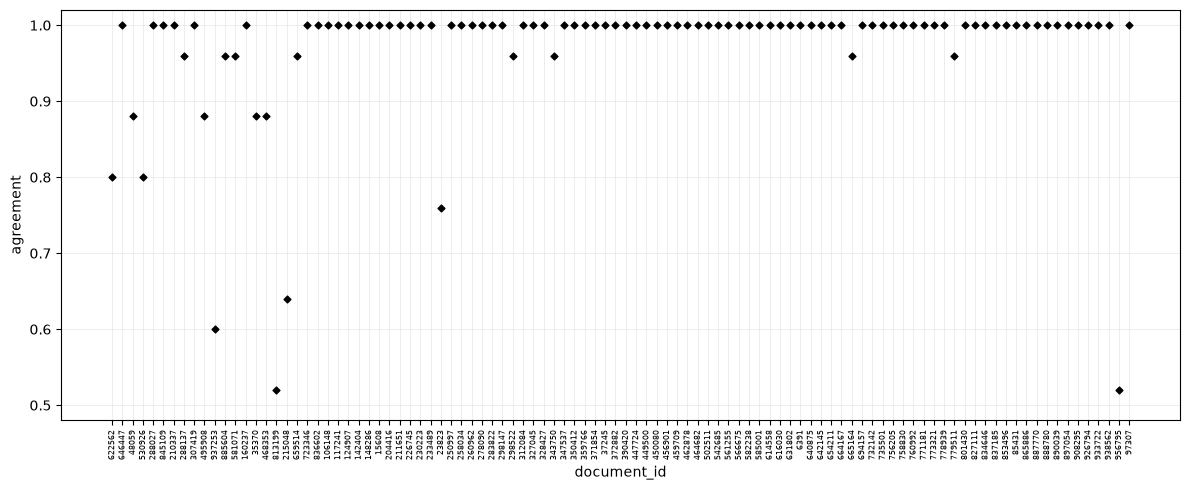

['622562',
 '646447',
 '48059',
 '530926',
 '288027',
 '845109',
 '210337',
 '288137',
 '307419',
 '495908',
 '937253',
 '885604',
 '581071',
 '160237',
 '35370',
 '468353',
 '813199',
 '215048',
 '659514',
 '723346',
 '836602',
 '106148',
 '117241',
 '124907',
 '142404',
 '148286',
 '15608',
 '204416',
 '211651',
 '226745',
 '230223',
 '233489',
 '23823',
 '250997',
 '258034',
 '260962',
 '278090',
 '283822',
 '298147',
 '298522',
 '312084',
 '327045',
 '328427',
 '343750',
 '347537',
 '350412',
 '359766',
 '371854',
 '37245',
 '372882',
 '390420',
 '447724',
 '449500',
 '450080',
 '456901',
 '459709',
 '462878',
 '464682',
 '502511',
 '542685',
 '561255',
 '566675',
 '582238',
 '585001',
 '614558',
 '616030',
 '631802',
 '6391',
 '640875',
 '642145',
 '654211',
 '664167',
 '665164',
 '694157',
 '732142',
 '735501',
 '756205',
 '758830',
 '760992',
 '771181',
 '773321',
 '778939',
 '779511',
 '801430',
 '827111',
 '834646',
 '837185',
 '853496',
 '85431',
 '865886',
 '887770',
 '88878

In [ ]:
# Parse saved outputs; this cell sends no requests.
review_coding(A0K_dir_consistency, document_order=order_0)

## 4. If high agreement, freeze final codebook 'A.0.k_final=0'

In [146]:
I_initial_codebook_freeze = A0K_codebook_path

## 5. If low agreement, revise

In [ ]:
# inputs
# codebook to revise, use codebook_A0K from previous section
revision_docs = codebook_input(
    dataset_0,
    pl.read_csv(
        A0K_dir_consistency / 'classifications.csv',
        schema_overrides={'document_id': pl.String, 'label': pl.String},
    ),
)
print(k)
revised_codebook_name = f"A.0.{k+1}"
A0K_revised_dir = Path('out', 'I_initial_codebook_generation', model_a_safe_name, 'codebooks_A0K', revised_codebook_name)
revise_prompt = Path('prompts/improve_codebook.txt').read_text(encoding='utf-8')

In [ ]:
dry_run = False  # Preview, then set False to submit once.
mode = "stream"
revision_response = revise_codebook(
    coded_documents = revision_docs,
    prompt = revise_prompt,
    model = model_a,
    out_dir = A0K_revised_dir,
    previous_codebook = codebook_A0K,
    mode = "stream",
    provider = None,
    dry_run = dry_run,
    api_key = api_key,
)
revision_response

In [ ]:
codebook_A0K_revise = parse_codebook(A0K_revised_dir, codebook_id=revised_codebook_name)
print(codebook_A0K_revise)

# increment k!

{
  "definition": "Emotive rhetoric is language used to make a speech or contribution emotionally forceful or persuasive through explicit emotional or moral evaluation, vivid depictions of harm or hardship, appeals to shared feelings or values, or pointed personal or political attack. Assess how the language is used in context: a serious topic, a policy disagreement, or an isolated mildly emphatic phrase is not enough by itself. The rhetoric must clearly meet at least one decision rule, or contain several cues that together create clear emotional force.",
  "decision_rules": [
    {
      "number": 1,
      "rule": "Code 1 when the speaker uses clearly charged emotional or moral language to praise, condemn, alarm, or rally—for example, describing conduct as shocking, evil, outrageous, unfair, or a disgrace, or using forceful language to demand urgent action. The word or phrase must function as a strong evaluation or emotional appeal in context; routine words such as “important” or “goo

After a revision, return to I.3 with the new `k` and `check_codebook_path = rev0_path`. Repeat until you manually freeze a revision.

# II. Iterative edits with new data

## 1. Model A codes dataset_j with Codebook A.(j-1).k_final, 25x
        Input: dataset_j, Codebook A.(j-1).k_final
        Output: coded dataset_j, 25x
        Empirical: Agreement across 25x

In [147]:
j = 1
k = 1

# codebook
codebook_AJK_name = f"A.{j-1}.{k}"
codebook_AJK_path = I_initial_codebook_freeze # if initial round, otherwise set to correct path
codebook_AJK = json.loads(
    codebook_AJK_path.read_text(encoding='utf-8')
)

# dataset
dataset_j = load_dataset(j)

In [148]:
# Preview first. Set False and rerun this cell to send.
dry_run = True
mode = "stream"
new_dataset_j_dir = Path('out', 'II_new_data', model_a_safe_name, f'dataset_{j}', codebook_AJK_name, mode)
new_data_request = run_classifications(
    documents = dataset_j,
    prompt = classify_w_codebook_prompt,
    codebook = codebook_AJK,
    model = model_a + ":nitro",
    out_dir = new_dataset_j_dir,
    api_key = api_key,
    provider = None,
    n_runs = 25,
    dry_run = dry_run,
)
new_data_request

{'model': 'openai/gpt-6-luna:nitro',
 'messages': [{'role': 'system',
   'content': 'You will receive a codebook and a set of parliamentary speeches held in the UK House of Commons.\n\nClassify each text according to whether the parliamentarian is using "emotive rhetoric." Use only the decision rules provided in the codebook, and no other information.\n\nUse only one of these labels:\n"1": The parliamentarian is using emotive rhetoric.\n"0": The parliamentarian is not using emotive rhetoric.\n\nFor each text, return:\n* label: Your classification, 1 or 0\n* citation: The number(s) of the decision rule(s) from the codebook that you used to make your decision\n* explanation: A brief explanation of the rationale for your classification and how you applied the decision rule(s) cited above\n\nReturn a JSON object containing "classifications" object matching the supplied schema. Use each exact input document_id as a key, with label, citation, and explanation inside its value.\nIMPORTANT: Mak

In [ ]:
# Batch only: check until completed. Skip for streaming.
if mode == "batch":
    batch = retrieve_classification_batch(api_key, dataset_j_dir)
    print(batch['status'], batch.get('request_counts'))

Krippendorff's alpha: 0.8979


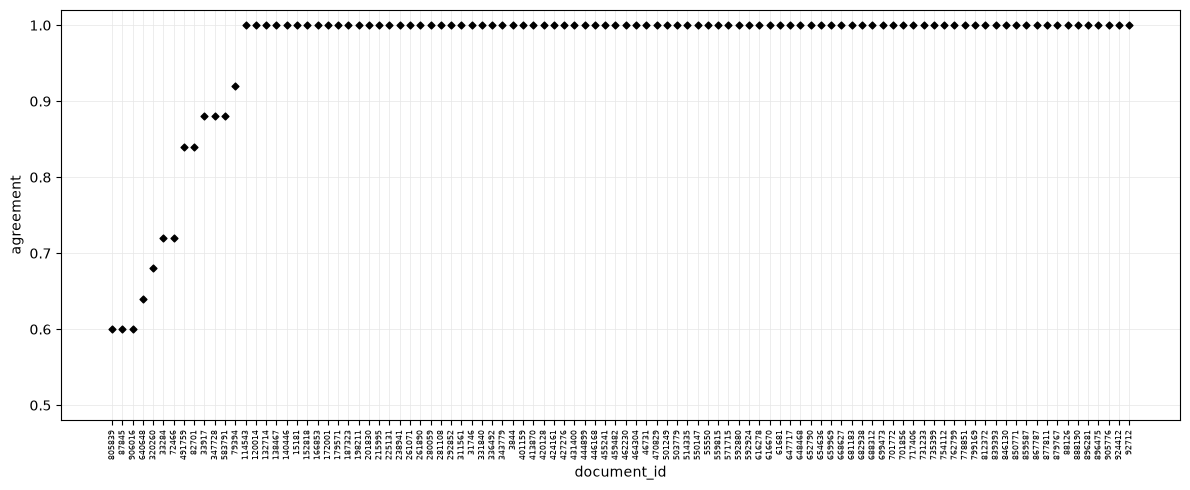

In [ ]:
# Parse saved outputs; this cell sends no requests.
order = review_coding(new_dataset_j_dir)

In [ ]:
II_codebook_freeze = codebook_AJK_path

WindowsPath('out/I_initial_codebook_generation/openai_gpt-6-luna/codebooks_A0K/A.0.1/codebook_A.0.1.json')

##    3. If low agreement across 25x, ask Model A to revise (additions only, no backtracking)
        Input: High disagreement cases from dataset_j in part (1), Codebook A.(j-1).k_final
        Output: Codebook A.j.0

In [ ]:
revj_id = f'A.{j}.0'
revj_mode = 'stream'
revj_provider = None
revj_input = codebook_input(load_documents(new_dir / 'documents.csv'), pl.read_csv(new_dir / 'classifications.csv', schema_overrides={'label': pl.String})).filter(pl.col('percent_1').is_between(0, 100, closed='none'))
revj_prompt = Path('prompts/improve_codebook.txt').read_text(encoding='utf-8') + '\nMake additions only. Preserve the existing definition and every existing rule and rule number verbatim. Append numbered rules to resolve disagreement without contradicting existing rules. Return the full codebook.'
revj_dir = root / 'codebooks' / revj_id / model_a_safe_name / revj_mode

In [ ]:
dry_run = True  # Preview, then set False to submit once.
revj_response = revise_codebook(
    revj_input, revj_prompt, model_a, api_key, revj_dir,
    dry_run=dry_run, mode=revj_mode, provider=revj_provider,
    previous_codebook=new_codebook,
)
revj_response

In [ ]:
if revj_mode == "batch":
    batch = retrieve_classification_batch(api_key, revj_dir)
    print(batch['status'])

In [ ]:
revj_parse_dir = revj_dir  # Or an existing generation folder.
revj_codebook = parse_codebook(revj_parse_dir, codebook_id=revj_id)
revj_path = revj_parse_dir / f'codebook_{revj_id}.json'
revj_codebook

##     4. Consistency check of A.j.k (starting with k=0): Model A codes (dataset_0...dataset_j) using Codebook A.j.k, 25x
        Input: (dataset_0...dataset_j), Codebook A.j.k
        Output: coded (dataset_0...dataset_j), 25x
        Empirical: Agreement across 25x

In [ ]:
k = 0
j = 1
cumulative_id = f'A.{j}.{k}'
cumulative_codebook_path = new_codebook_path  # Select the revision being checked.
cumulative_codebook = json.loads(cumulative_codebook_path.read_text(encoding='utf-8'))
cumulative_documents = pl.concat([load_dataset(number) for number in range(j + 1)])
cumulative_model = model_a
cumulative_mode = 'batch'
cumulative_provider = None
cumulative_prompt = classification_prompt
cumulative_dir = root / 'II_consistency' / f'datasets_0_to_{j}' / cumulative_id / model_a_safe_name / cumulative_mode

In [ ]:
# Preview first. Set False and rerun this cell to send.
dry_run = True
cumulative_request = run_classifications(
    cumulative_documents, cumulative_prompt, cumulative_model, api_key, cumulative_dir,
    mode=cumulative_mode, provider=cumulative_provider, n_runs=25,
    dry_run=dry_run, codebook=cumulative_codebook,
)
cumulative_request

In [ ]:
# Batch only: check until completed. Skip for streaming.
if cumulative_mode == "batch":
    batch = retrieve_classification_batch(api_key, cumulative_dir)
    print(batch['status'], batch.get('request_counts'))

In [ ]:
# Parse saved outputs; this cell sends no requests.
cumulative_parse_dir = cumulative_dir  # Or enter an existing output directory.
review_coding(cumulative_parse_dir)

### II.5?6 Freeze or repeat
If accepted, freeze below, increment `j`, and return to II.1. Otherwise use the revision section with disagreement cases from `cumulative_parse_dir`, the current cumulative codebook, and the next ID `A.j.(k+1)`, then repeat II.4.

In [ ]:
# freeze_codebook(cumulative_codebook_path, root / 'frozen', f'A.{j}.k_final', 'Accepted after cumulative consistency check.')

## III. Agreement with a new model
Model B (and Model A, if not already existing) codes dataset_j with Codebook Ab.(j-1).k_final

        Input: dataset_j, Codebook Ab.(j-1).k_final
        Output: B's coded dataset_j, 25x
        Empirical: Agreement between A and B's coding distribution over 25x on dataset_j

In [186]:
j=1

# codebook_Ab_JK_path = II_codebook_freeze # if first run, otherwise set to correct path
codebook_Ab_JK_path = codebook_cross_model_revise
codebook_Ab_JK = json.loads(
    codebook_Ab_JK_path.read_text(encoding='utf-8')
)
codebook_Ab_JK_name = f"codebook_Ab.{j}.{0}"

dataset_j = load_dataset(j)

In [187]:
dry_run = True
mode = "batch"
model_b = 'deepseek/deepseek-v4.1-flash'
model_b_safe_name = model_folder(model_b)
cross_code_b_dir = Path("out", "III_new_model", f'dataset_{j}', codebook_Ab_JK_name, model_b_safe_name, mode)
new_model_request = run_classifications(
    documents = dataset_j,
    prompt = classify_w_codebook_prompt,
    codebook = codebook_Ab_JK,
    model = model_b + ":nitro",
    out_dir = cross_code_b_dir,
    mode = mode,
    api_key = api_key,
    provider = None,
    n_runs = 25,
    dry_run = dry_run,
)
new_model_request

{'endpoint': '/v1/chat/completions',
 'model': 'deepseek/deepseek-v4.1-flash:nitro',
 'completion_window': '24h',
 'requests': [{'custom_id': 'run_01',
   'body': {'messages': [{'role': 'system',
      'content': 'You will receive a codebook and a set of parliamentary speeches held in the UK House of Commons.\n\nClassify each text according to whether the parliamentarian is using "emotive rhetoric." Use only the decision rules provided in the codebook, and no other information.\n\nUse only one of these labels:\n"1": The parliamentarian is using emotive rhetoric.\n"0": The parliamentarian is not using emotive rhetoric.\n\nFor each text, return:\n* label: Your classification, 1 or 0\n* citation: The number(s) of the decision rule(s) from the codebook that you used to make your decision\n* explanation: A brief explanation of the rationale for your classification and how you applied the decision rule(s) cited above\n\nReturn a JSON object containing "classifications" object matching the su

In [189]:
# Batch only: check until completed. Skip for streaming.
if mode == "batch":
    batch = retrieve_classification_batch(api_key, cross_code_b_dir)
    print(batch['status'], batch.get('request_counts'))

completed {'total': 25, 'completed': 25, 'failed': 0}


Krippendorff's alpha: 0.9248


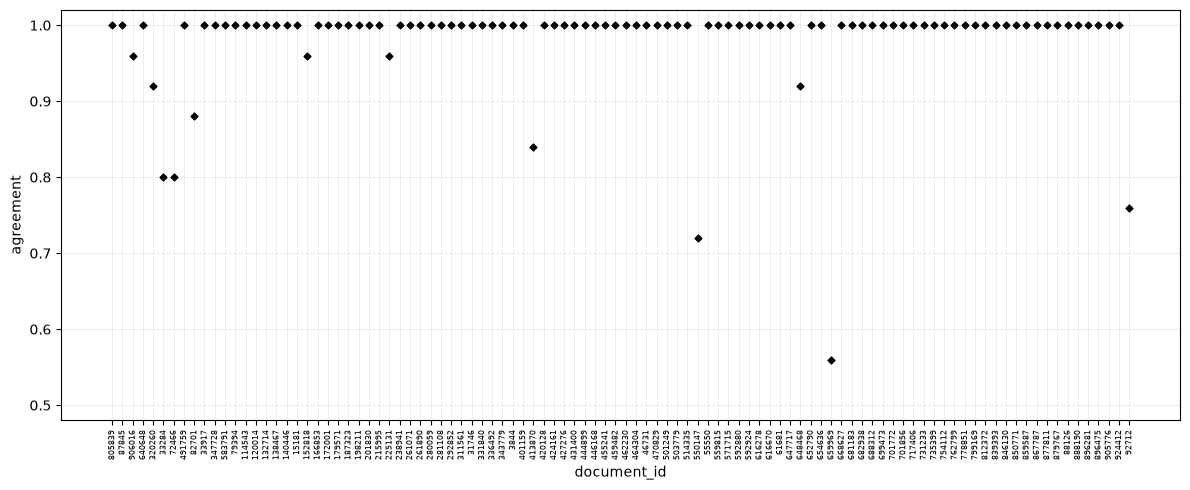

In [190]:
# Parse saved outputs; this cell sends no requests.
order = review_coding(cross_code_b_dir, document_order = order)

Mean A-B absolute difference in % of 25 runs coded LABEL=1: 0.0864
A-B Pearson correlation between % of 25 runs coded LABEL=1: 0.8693
Average over 25 runs of within-run pairwise Krippendorff's alpha: 0.7804


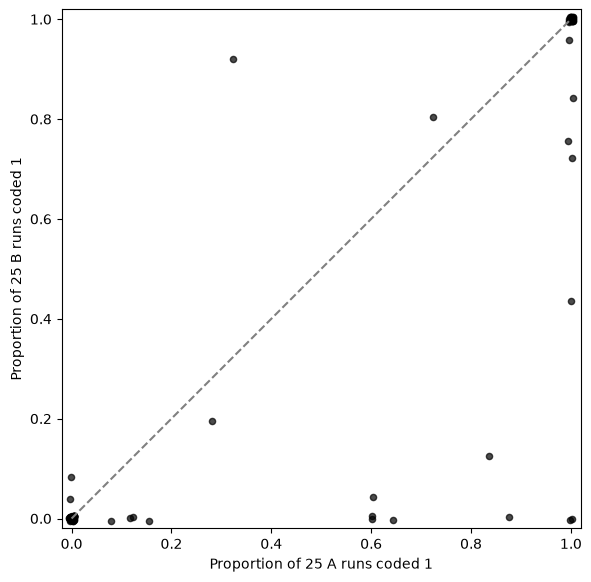

(shape: (100, 4)
 ┌─────────────┬─────────────┬─────────────┬───────────────┐
 │ document_id ┆ percent_1_A ┆ percent_1_B ┆ difference_pp │
 │ ---         ┆ ---         ┆ ---         ┆ ---           │
 │ str         ┆ f64         ┆ f64         ┆ f64           │
 ╞═════════════╪═════════════╪═════════════╪═══════════════╡
 │ 238941      ┆ 1.0         ┆ 0.0         ┆ 1.0           │
 │ 616278      ┆ 1.0         ┆ 0.0         ┆ 1.0           │
 │ 583791      ┆ 0.88        ┆ 0.0         ┆ 0.88          │
 │ 82701       ┆ 0.84        ┆ 0.12        ┆ 0.72          │
 │ 640648      ┆ 0.64        ┆ 0.0         ┆ 0.64          │
 │ 320260      ┆ 0.32        ┆ 0.92        ┆ 0.6           │
 │ 805839      ┆ 0.6         ┆ 0.0         ┆ 0.6           │
 │ 87845       ┆ 0.6         ┆ 0.0         ┆ 0.6           │
 │ 659969      ┆ 1.0         ┆ 0.44        ┆ 0.56          │
 │ 906016      ┆ 0.6         ┆ 0.04        ┆ 0.56          │
 │ 550147      ┆ 1.0         ┆ 0.72        ┆ 0.28          │
 │ 9271

In [191]:
compare_models(new_dataset_j_dir, cross_code_b_dir)

## 2. revise based on AB disagreements

In [ ]:
k = 0

dataset_j = load_dataset(j)
revision_docs = codebook_input(
    dataset_j,
    pl.read_csv(
        cross_code_b_dir / 'classifications.csv',
        schema_overrides={'document_id': pl.String, 'label': pl.String},
    ),
)

revise_prompt = Path('prompts/improve_codebook.txt').read_text(encoding='utf-8')


In [166]:
dry_run = False  # Preview, then set False to submit once.
cross_model_revise_dir = Path("out", "III_new_model", f"dataset_{j}", codebook_Ab_JK_name)
revision_response = revise_codebook(
    coded_documents = revision_docs,
    prompt = revise_prompt,
    model = model_a,
    out_dir = cross_model_revise_dir,
    previous_codebook = codebook_Ab_JK,
    mode = "stream",
    provider = None,
    dry_run = dry_run,
    api_key = api_key,
)
revision_response

{'choices': [{'message': {'role': 'assistant',
    'content': '{\n  "codebook": {\n    "definition": "Emotive rhetoric is language used to make a speech or contribution emotionally forceful or persuasive through explicit emotional or moral evaluation, vivid depictions of harm or hardship, appeals to shared feelings or values, or pointed personal or political attack. Assess the language\'s function in context, not the seriousness of the subject, the speaker\'s policy position, or the speech format. A serious topic, factual consequence, routine expression of sympathy or support, or isolated mildly emphatic phrase is not enough by itself. Code 1 when at least one decision rule is clearly met, or when several cues together create clear emotional force.",\n    "decision_rules": [\n      {\n        "number": 1,\n        "rule": "Code 1 when the speaker uses clearly charged emotional or moral language to praise, condemn, alarm, or rally—for example, describing conduct as shocking, evil, outra

In [169]:
codebook_cross_model_revise = parse_codebook(cross_model_revise_dir, codebook_id=f"Ab.{j}.{k}")
print(codebook_cross_model_revise)

{
  "definition": "Emotive rhetoric is language used to make a speech or contribution emotionally forceful or persuasive through explicit emotional or moral evaluation, vivid depictions of harm or hardship, appeals to shared feelings or values, or pointed personal or political attack. Assess the language's function in context, not the seriousness of the subject, the speaker's policy position, or the speech format. A serious topic, factual consequence, routine expression of sympathy or support, or isolated mildly emphatic phrase is not enough by itself. Code 1 when at least one decision rule is clearly met, or when several cues together create clear emotional force.",
  "decision_rules": [
    {
      "number": 1,
      "rule": "Code 1 when the speaker uses clearly charged emotional or moral language to praise, condemn, alarm, or rally—for example, describing conduct as shocking, evil, outrageous, unfair, or a disgrace, or using forceful language to demand urgent action. Judge the word 

### III.4?6 Cumulative checks and final acceptance
After a revision, set `shared_codebook_path = revab_path`, load that codebook, set `shared_id` to its `Ab.j.k` ID, and use `shared_documents = pl.concat([load_dataset(number) for number in range(j + 1)])`. Rerun both III.1 sections in new folders whose dataset component is `datasets_0_to_j`; compare again. For another revision, use the cumulative comparison cases and increment `k`. Freeze manually once acceptable; increment `j` and return to III.1 as specified.

In [ ]:
# Final acceptance (run deliberately after reviewing both models):
# freeze_codebook(shared_codebook_path, root / 'frozen', 'Ab.final', 'Accepted after A?B distribution review.')